# Name: Ronsam Erasmus
# Student Number: ST10482612


In [2]:
import numpy as np #for arithmetical operations
import pandas as pd #for dataframes
import matplotlib.pyplot as plt #to plot graphs
from sklearn.model_selection import train_test_split #to split data into training and test sets
from sklearn.preprocessing import LabelEncoder #to encode variable strings into numerics
from sklearn.linear_model import LogisticRegression #for Logistic regression model
from sklearn import svm #for support vector machine
from sklearn.preprocessing import MinMaxScaler  #to scale data
import seaborn as sns   #for more graphs ie heatmaps

df_raw_data = pd.read_csv('C:/Users/Ronsa/OneDrive/Documents/PGDIP Data Analysis/Research Project/Project/Code/archive/UCI_Credit_Card.csv')
df_raw_data.head()
df_raw_data.tail()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
29995,29996,220000.0,1,3,1,39,0,0,0,0,...,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,1,3,2,43,-1,-1,-1,-1,...,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,1,2,2,37,4,3,2,-1,...,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,1,3,1,41,1,-1,0,0,...,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1
29999,30000,50000.0,1,2,1,46,0,0,0,0,...,36535.0,32428.0,15313.0,2078.0,1800.0,1430.0,1000.0,1000.0,1000.0,1


In [3]:
df_raw_data.shape


(30000, 25)

In [4]:
df_raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

In [5]:
df_raw_data.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [6]:
df_raw_data=df_raw_data.drop(columns=['ID'])

In [7]:
df_raw_data.isna().sum()

LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

In [8]:
df_raw_data.isnull().sum()

LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

In [9]:
df_raw_data.duplicated().sum()

np.int64(35)

In [10]:
df_dedup=df_raw_data.drop_duplicates()
df_dedup.shape

(29965, 24)

In [11]:
num_cols = df_dedup.select_dtypes(include=['float64','int64']).columns
print(num_cols)


Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='str')


In [12]:
for col in num_cols:
    Qrt1 = df_dedup[col].quantile(0.25)
    Qrt3 = df_dedup[col].quantile(0.75)
    IQR=Qrt3-Qrt1
    lower_bound=Qrt1 - 1.5*IQR
    upper_bound=Qrt3 + 1.5* IQR
    outliers= df_dedup[(df_dedup[col]< lower_bound)|(df_dedup[col]> upper_bound)]
    if len(outliers) > 0 :
        print(f"{col}: {len(outliers)} outliers")

LIMIT_BAL: 167 outliers
EDUCATION: 454 outliers
AGE: 272 outliers
PAY_0: 3129 outliers
PAY_2: 4409 outliers
PAY_3: 4208 outliers
PAY_4: 3507 outliers
PAY_5: 2967 outliers
PAY_6: 3078 outliers
BILL_AMT1: 2386 outliers
BILL_AMT2: 2390 outliers
BILL_AMT3: 2469 outliers
BILL_AMT4: 2616 outliers
BILL_AMT5: 2724 outliers
BILL_AMT6: 2688 outliers
PAY_AMT1: 2742 outliers
PAY_AMT2: 2723 outliers
PAY_AMT3: 2596 outliers
PAY_AMT4: 2993 outliers
PAY_AMT5: 2944 outliers
PAY_AMT6: 2960 outliers
default.payment.next.month: 6630 outliers


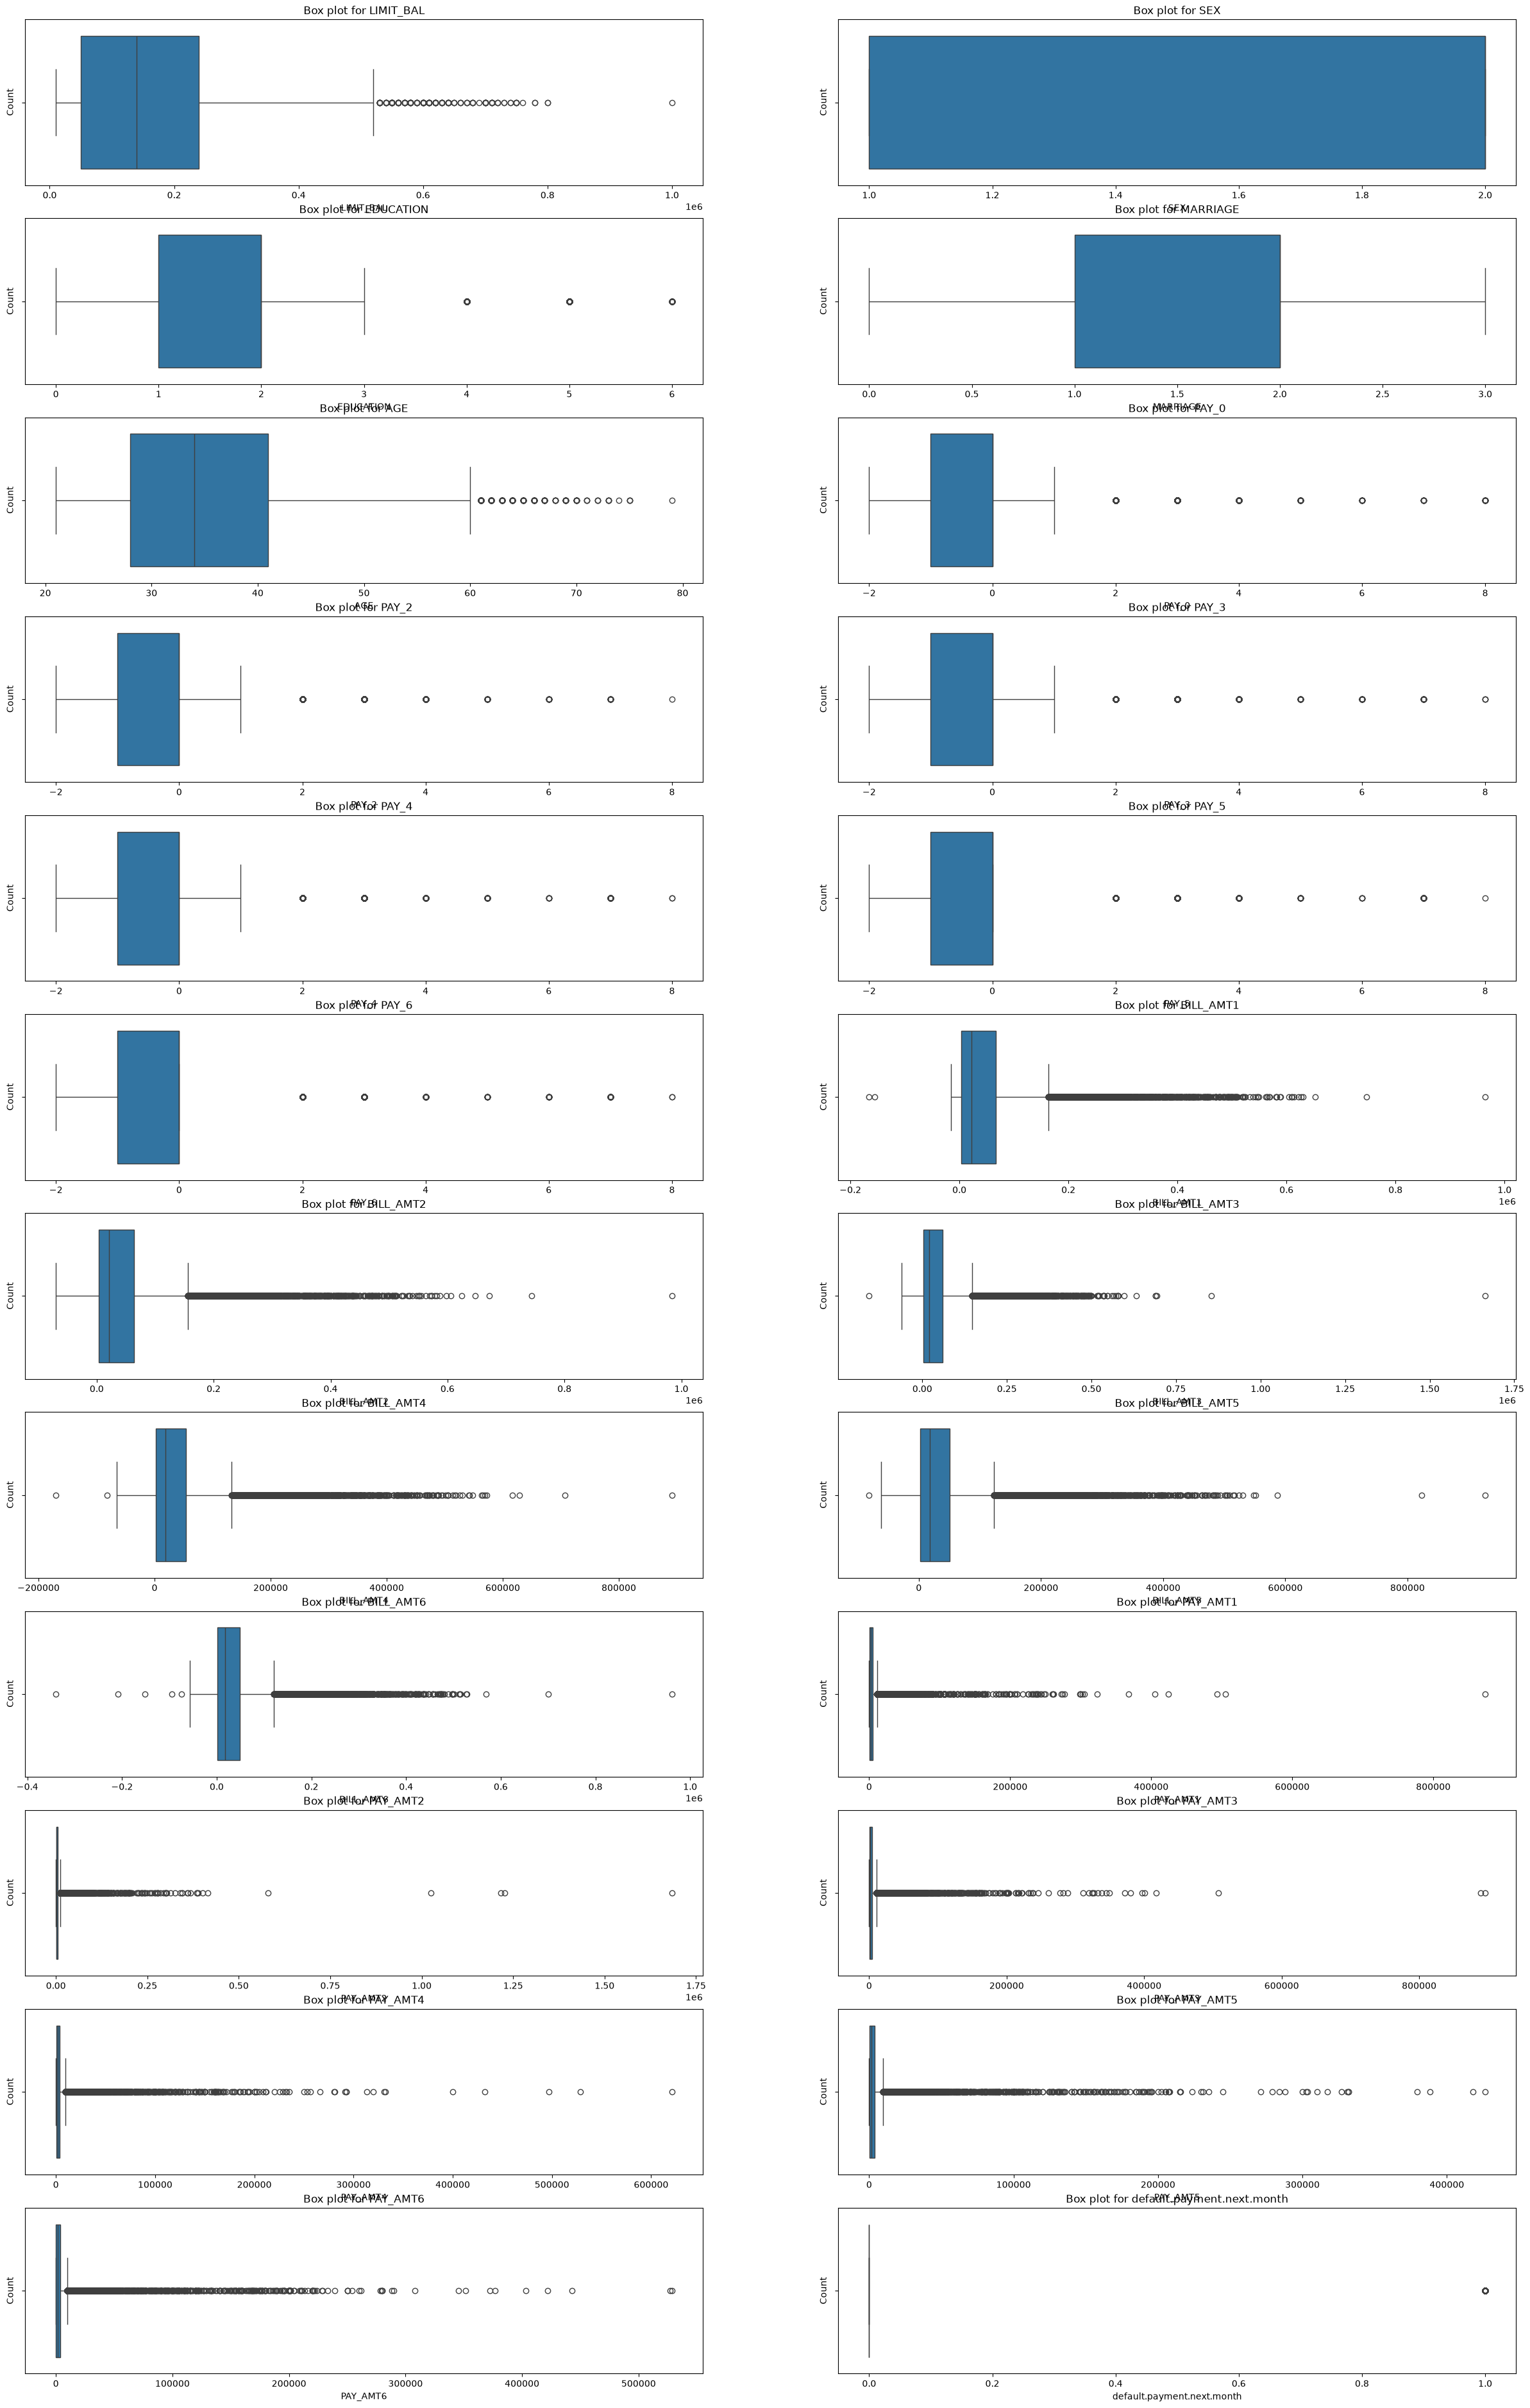

In [13]:
plt.figure(figsize=(30, len(num_cols) * 4))
for idx, feature in enumerate(num_cols, 1):
        plt.subplot(len(num_cols), 2, idx)
        sns.boxplot(data=df_dedup, x=feature)
        plt.title(f"Box plot for {feature}")
        plt.xlabel(feature)
        plt.ylabel("Count")

plt.show()


In [14]:
num_cols = (
    df_dedup.select_dtypes(include=['float64', 'int64'])
    .columns.drop('default.payment.next.month')
)

for col in num_cols:
    Q1 = df_dedup[col].quantile(0.25)
    Q3 = df_dedup[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_dedup[col] = (
        df_dedup[col]
        .astype(float)
        .clip(lower=lower_bound, upper=upper_bound)
    )

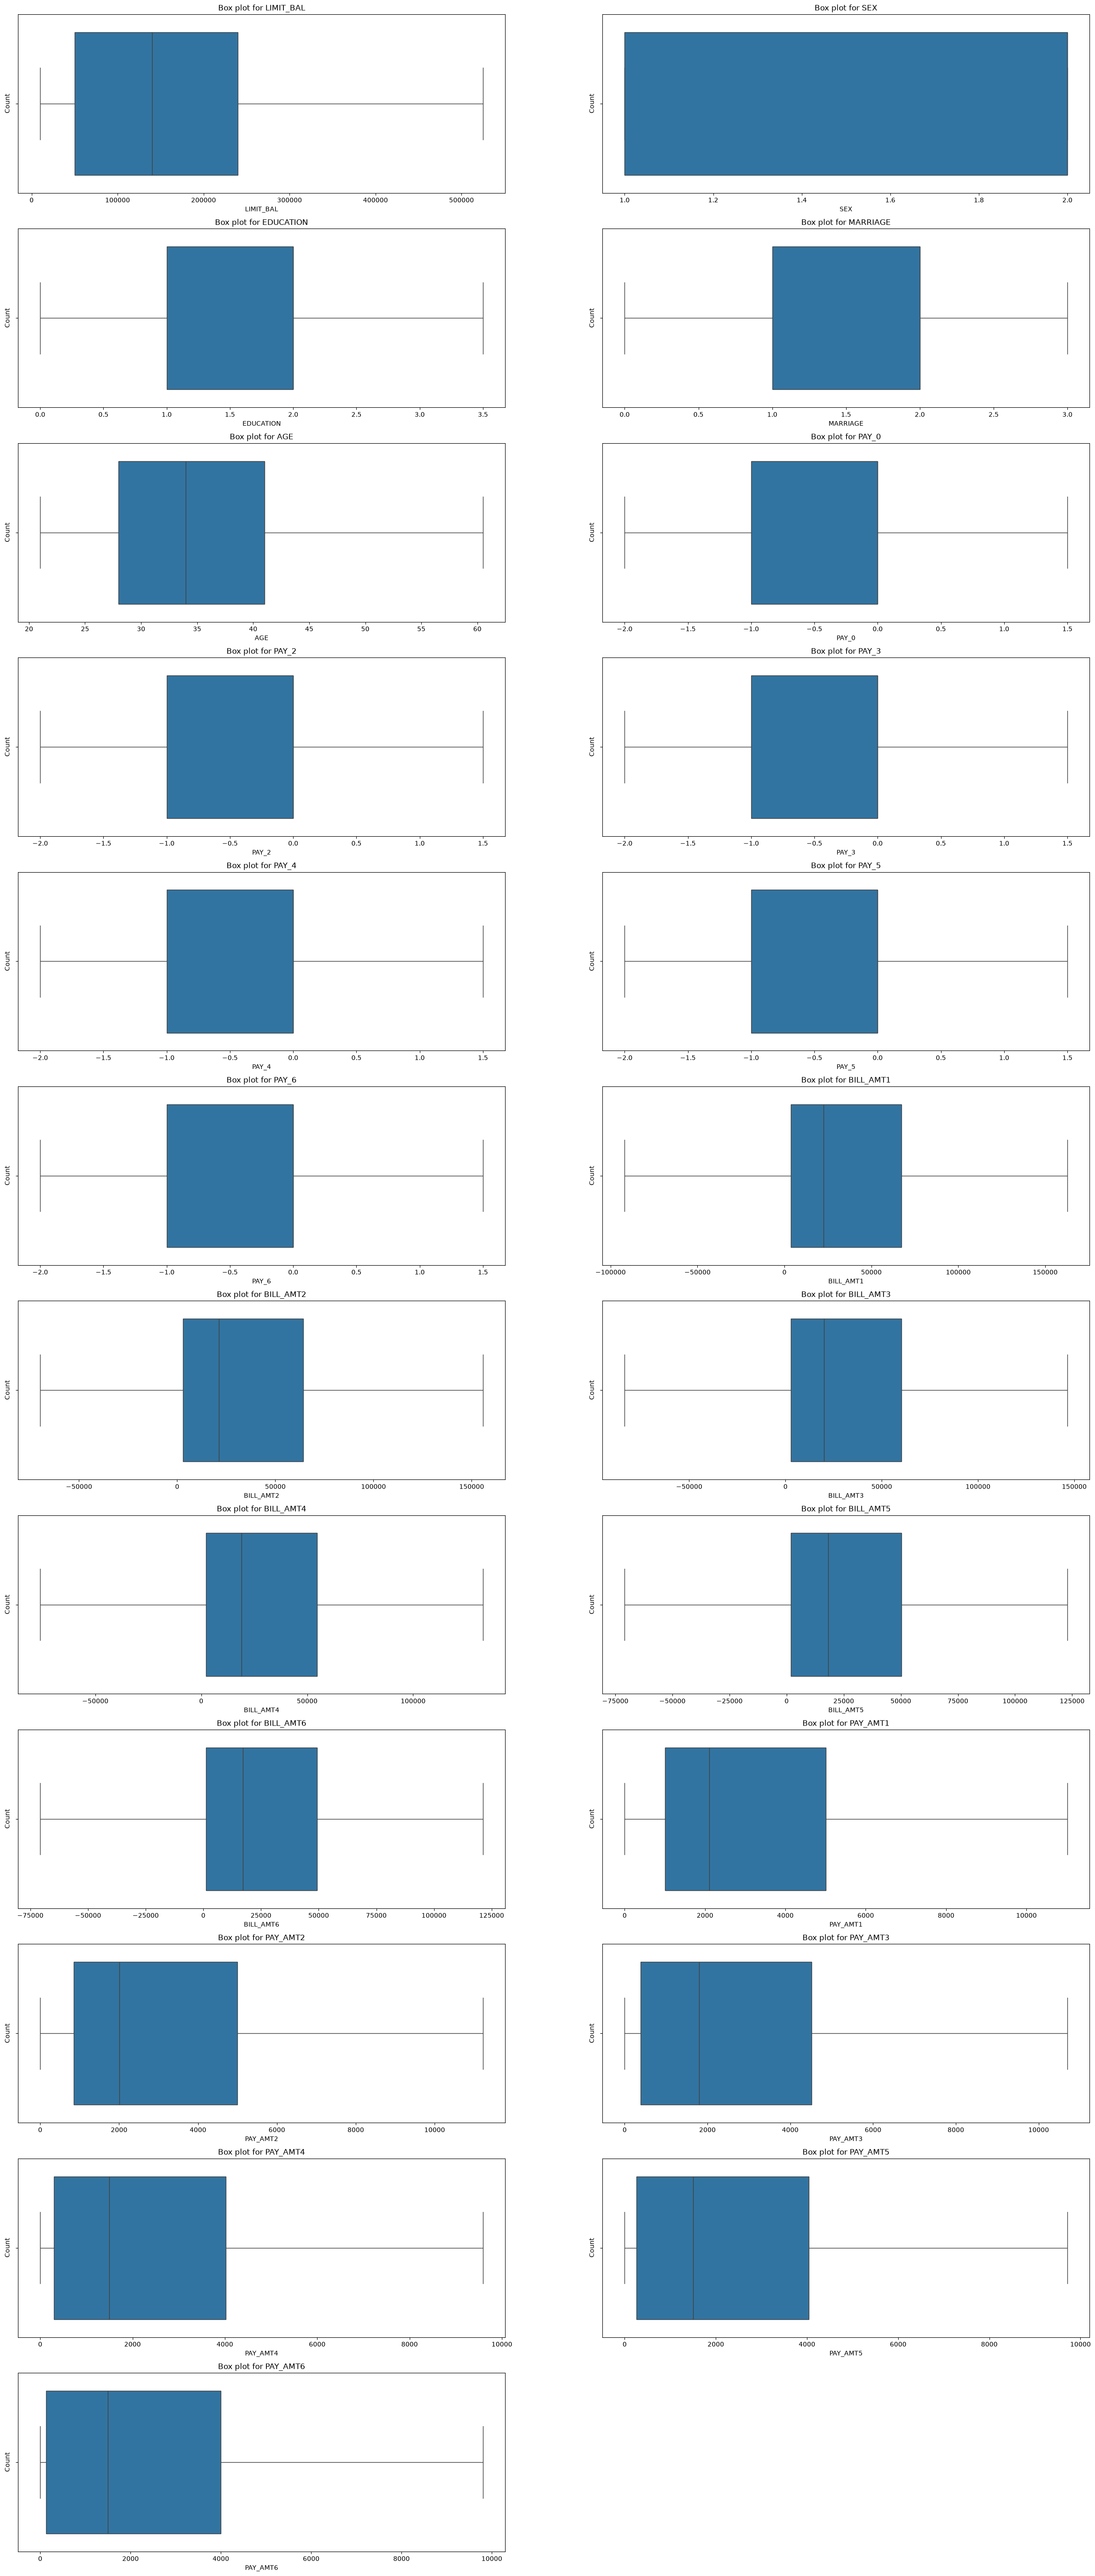

In [15]:
plt.figure(figsize=(30, len(num_cols) * 6))
for idx, feature in enumerate(num_cols, 1):
        plt.subplot(len(num_cols), 2, idx)
        sns.boxplot(data=df_dedup, x=feature)
        plt.title(f"Box plot for {feature}")
        plt.xlabel(feature)
        plt.ylabel("Count")

plt.show()

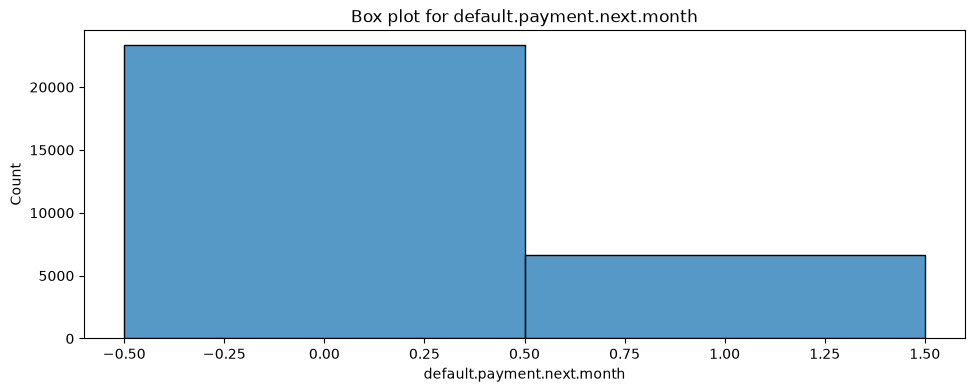

In [16]:
int_columns = df_dedup.select_dtypes(include=["int"]).columns

plt.figure(figsize=(25, len(int_columns) * 4))
for idx, feature in enumerate(int_columns, 1):
    plt.subplot(len(int_columns), 2, idx)
    sns.histplot(data=df_dedup, x=feature, discrete=True)
    plt.title(f"Box plot for {feature}")
    plt.xlabel(feature)
    plt.ylabel("Count")

plt.show()

In [17]:

pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
             'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
                'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

# 1. WorstPaymentStatus
df_dedup.loc[:, 'WorstPaymentStatus'] = (df_dedup[pay_cols].max(axis=1))

# 2. NumDelinq (count months with delinquency)
df_dedup.loc[:, 'NumDelinq'] = (df_dedup[pay_cols] > 0).sum(axis=1)
# 3. RecentDelinqFlag (most recent month delinquent)
df_dedup.loc[:, 'RecentDelinqFlag'] = (df_dedup['PAY_0'] > 0).astype(int)
# 4. AvgUtil
df_dedup.loc[:, 'AvgUtil'] = (df_dedup[bill_cols].mean(axis=1).div(df_dedup['LIMIT_BAL']))

# 5. MaxUtil
df_dedup.loc[:, 'MaxUtil'] = (df_dedup[bill_cols].max(axis=1).div(df_dedup['LIMIT_BAL']))

# 6. LatestPayRatio
df_dedup.loc[:, 'LatestPayRatio'] = (df_dedup['PAY_AMT1'].div(df_dedup['BILL_AMT1'].replace(0, np.nan)))

# 7. AvgPayRatio
df_dedup.loc[:, 'AvgPayRatio'] = (df_dedup[pay_amt_cols].sum(axis=1).div(df_dedup[bill_cols].sum(axis=1).replace(0, np.nan)))

# 8. BalanceGrowth
df_dedup.loc[:, 'BalanceGrowth'] = ((df_dedup['BILL_AMT1'] - df_dedup['BILL_AMT6']).div(df_dedup['BILL_AMT6'].abs() + 1))

# 9. PaymentCapacity
df_dedup.loc[:, 'PaymentCapacity'] = (df_dedup[pay_amt_cols].sum(axis=1).div(df_dedup['LIMIT_BAL']))

# 10. UtilStd
df_dedup.loc[:, 'UtilStd'] = (df_dedup[bill_cols].div(df_dedup['LIMIT_BAL'], axis=0).std(axis=1))

In [18]:
df_dedup.describe()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,WorstPaymentStatus,NumDelinq,RecentDelinqFlag,AvgUtil,MaxUtil,LatestPayRatio,AvgPayRatio,BalanceGrowth,PaymentCapacity,UtilStd
count,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,...,29965.000000,29965.000000,29965.000000,29965.000000,29965.000000,27987.000000,29125.000000,29965.000000,29965.000000,29965.000000
mean,166924.567996,1.603738,1.833306,1.551877,35.451894,-0.094160,-0.230552,-0.257901,-0.302236,-0.337611,...,0.232087,0.834273,0.226798,0.352601,0.467712,-1.344044,0.272708,2135.938129,0.165962,0.093202
std,128023.825407,0.489128,0.724379,0.521997,9.107477,0.951423,0.990704,0.994460,0.968578,0.946777,...,1.007062,1.554821,0.418768,0.334243,0.408177,83.133848,4.243978,12806.039332,0.175313,0.121394
min,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-2.000000,0.000000,0.000000,-0.232590,-0.100000,-11020.000000,-546.928571,-2628.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,0.000000,0.000000,0.000000,0.030303,0.071108,0.037771,0.044554,-0.132717,0.062407,0.015077
50%,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.272484,0.398200,0.063723,0.075285,0.205166,0.132615,0.044328
75%,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.500000,1.000000,0.000000,0.632750,0.847950,0.228912,0.410451,1.479258,0.211720,0.119363
max,525000.000000,2.000000,3.500000,3.000000,60.500000,1.500000,1.500000,1.500000,1.500000,1.500000,...,1.500000,6.000000,1.000000,5.364308,6.455300,3673.333333,97.971014,162757.500000,3.280350,2.542808


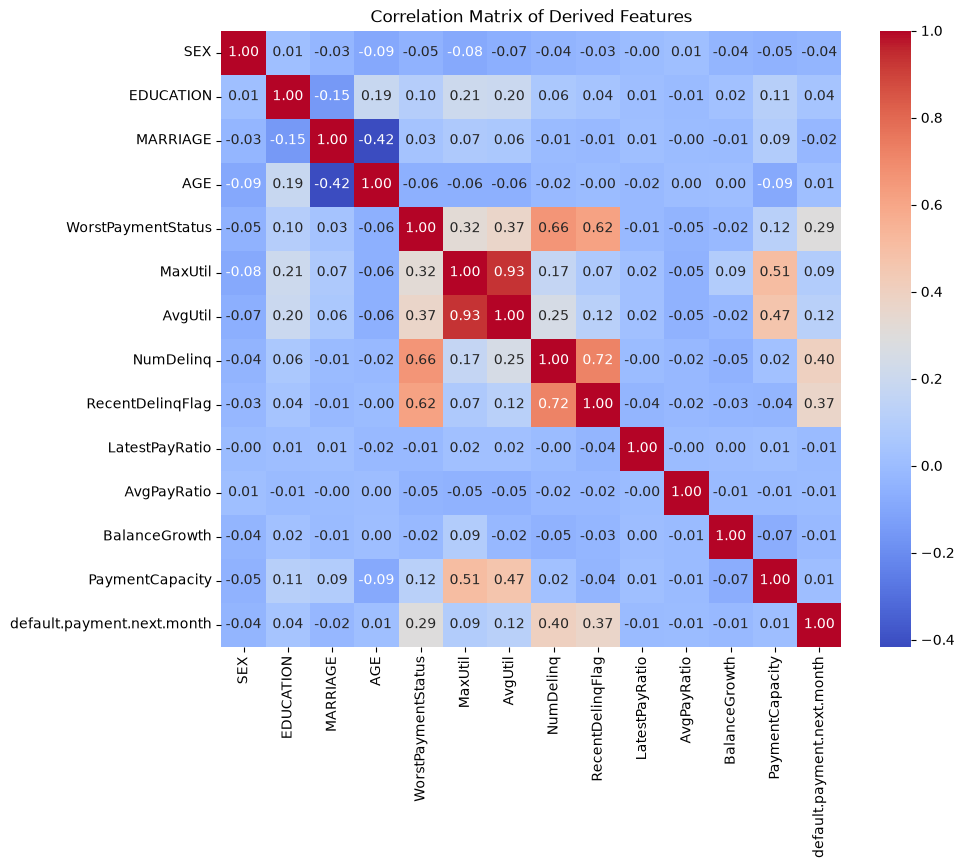

In [19]:
derived_features = ['SEX' ,'EDUCATION' ,'MARRIAGE' ,'AGE' ,
    'WorstPaymentStatus',
    'MaxUtil',
    'AvgUtil',
    'NumDelinq',
    'RecentDelinqFlag',
    'LatestPayRatio',
    'AvgPayRatio',
    'BalanceGrowth',
    'PaymentCapacity','default.payment.next.month'
]

corr = df_dedup[derived_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Derived Features')
plt.show()

In [20]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_features = [
    'SEX',
    'EDUCATION',
    'MARRIAGE',
    'AGE',
    'WorstPaymentStatus',
    'MaxUtil',
    'AvgUtil',
    'NumDelinq',
    'RecentDelinqFlag',
    'LatestPayRatio',
    'AvgPayRatio',
    'BalanceGrowth',
    'PaymentCapacity'
]

X = df_dedup[vif_features].copy()


X = X.replace([float('inf'), float('-inf')], pd.NA)
X = X.dropna()

# Calculate VIF
vif_df = pd.DataFrame({'Feature': X.columns,'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})

# Sort by highest VIF
vif_df = vif_df.sort_values('VIF', ascending=False)
print(vif_df)

               Feature       VIF
5              MaxUtil  8.992199
6              AvgUtil  8.701046
7            NumDelinq  3.016072
8     RecentDelinqFlag  2.594664
4   WorstPaymentStatus  2.132186
12     PaymentCapacity  1.347308
3                  AGE  1.261472
2             MARRIAGE  1.230981
11       BalanceGrowth  1.133422
1            EDUCATION  1.110000
0                  SEX  1.028032
9       LatestPayRatio  1.004091
10         AvgPayRatio  1.003579


In [21]:
selected_features = [
    'NumDelinq',
    'WorstPaymentStatus',
    'AvgUtil',
    'AGE',
    'EDUCATION'
]

In [22]:
scaler = MinMaxScaler()
y = df_dedup['default.payment.next.month']

X = df_dedup[selected_features]
X_scaled = scaler.fit_transform(X)
x_train,x_test,y_train,y_test = train_test_split(X_scaled,y,random_state=42,test_size=0.3,stratify=y) #split into training and test
print(f'(x_train_obs,x_train_var)={x_train.shape}')
print(f'(x_test_obs,x_test_var)={x_test.shape}')

(x_train_obs,x_train_var)=(20975, 5)
(x_test_obs,x_test_var)=(8990, 5)


In [23]:
regressor = LogisticRegression()

In [24]:
regressor.fit(x_train,y_train)
prediction = regressor.predict(x_test)
feature_names = X.columns
print(feature_names)
regressor.coef_

Index(['NumDelinq', 'WorstPaymentStatus', 'AvgUtil', 'AGE', 'EDUCATION'], dtype='str')


array([[ 2.4719265 ,  1.02076665, -0.00818609,  0.22555552, -0.01338525]])

In [27]:
regressor.intercept_

array([-2.48863285])

In [28]:
score=regressor.score(x_test,y_test)
print(f'Model accuracy is {score}')

Model accuracy is 0.807119021134594


In [29]:
# Predictions
y_prob_lr = regressor.predict(x_test).ravel()
y_pred_lr = (y_prob_lr > 0.5).astype(int)


from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import confusion_matrix,classification_report

y_test_bin = label_binarize(y_test, classes=[0, 1])

auc_macro = roc_auc_score(
    y_test_bin,
    y_prob_lr,
    multi_class='ovr',
    average='macro'
)

auc_weighted = roc_auc_score(
    y_test_bin,
    y_prob_lr,
    multi_class='ovr',
    average='weighted'
)

print("Macro ROC-AUC:", round(auc_macro, 4))
print("Weighted ROC-AUC:", round(auc_weighted, 4))


print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))
print(classification_report(y_test, y_prob_lr))

Macro ROC-AUC: 0.6127
Weighted ROC-AUC: 0.6127
ROC-AUC: 0.6126929076927816
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7001
           1       0.66      0.26      0.38      1989

    accuracy                           0.81      8990
   macro avg       0.74      0.61      0.63      8990
weighted avg       0.79      0.81      0.77      8990



Classification Report LR:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7001
           1       0.66      0.26      0.38      1989

    accuracy                           0.81      8990
   macro avg       0.74      0.61      0.63      8990
weighted avg       0.79      0.81      0.77      8990



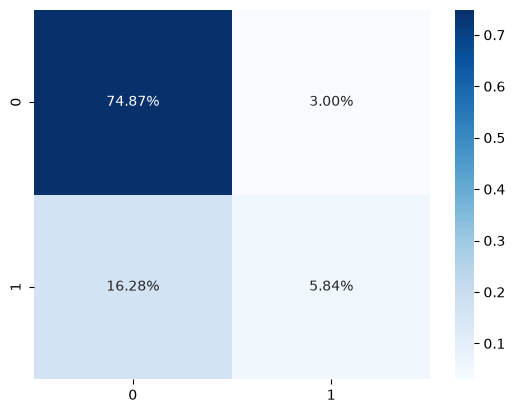

In [30]:
from sklearn.metrics import confusion_matrix,classification_report
y_pred = regressor.predict(x_test)
cf_matrix = confusion_matrix(y_test, y_pred)
import seaborn as sns
sns.heatmap(cf_matrix/np.sum(cf_matrix), annot=True,
            fmt='.2%', cmap='Blues')
class_report = classification_report(y_test, y_pred)
print("Classification Report LR:")
print(class_report)

In [31]:
param_grid = [
    {'penalty':['l1','l2','elasticnet','none'],
    'C' : np.logspace(-4,4,20),
    'solver': ['lbfgs','newton-cg','liblinear','sag','saga'],
    'max_iter'  : [100,1000,2500,5000]
}
]


In [ ]:
from sklearn.model_selection import GridSearchCV
clf_lr = GridSearchCV(regressor,param_grid = param_grid, cv = 3, verbose=True,n_jobs=-1)
clf_lr

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'C': array([1.0000...00000000e+04]), 'max_iter': [100, 1000, ...], 'penalty': ['l1', 'l2', ...], 'solver': ['lbfgs', 'newton-cg', ...]}]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_aut

In [33]:
best_clf_lr = clf_lr.fit(x_train,y_train)
best_LR_model=best_clf_lr.best_estimator_

Fitting 3 folds for each of 1600 candidates, totalling 4800 fits


c:\Users\Ronsa\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
2880 fits failed out of a total of 4800.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
240 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Ronsa\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\Ronsa\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Ronsa\A

In [34]:
print(f'Accuracy best - : {clf_lr.score(x_test,y_test):.5f}')
print(f'Accuracy regressor - : {regressor.score(x_test,y_test):.5f}')
best_LR_model.coef_

Accuracy best - : 0.80712
Accuracy regressor - : 0.80712


array([[2.32290133, 0.78519967, 0.        , 0.        , 0.        ]])

In [35]:
best_LR_model.intercept_

array([-2.21275242])

Classification Report LR(Tuned):
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7001
           1       0.66      0.26      0.38      1989

    accuracy                           0.81      8990
   macro avg       0.74      0.61      0.63      8990
weighted avg       0.79      0.81      0.77      8990



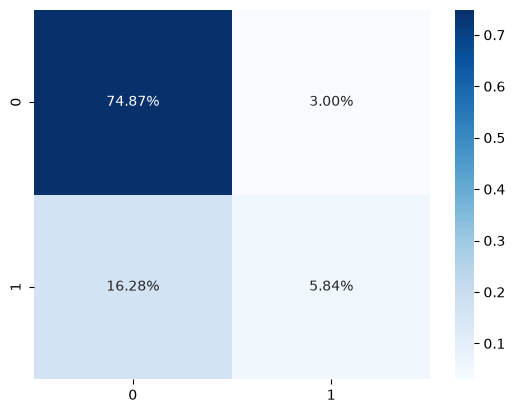

In [36]:
from sklearn.metrics import confusion_matrix
y_pred_lr = clf_lr.predict(x_test)
cf_matrix = confusion_matrix(y_test, y_pred_lr)
import seaborn as sns
sns.heatmap(cf_matrix/np.sum(cf_matrix), annot=True,
            fmt='.2%', cmap='Blues')
class_report = classification_report(y_test, y_pred_lr)
print("Classification Report LR(Tuned):")
print(class_report)

In [37]:
clf_svm = svm.SVC(probability=True)
clf_svm.fit(x_train,y_train)

c:\Users\Ronsa\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [38]:
score_svm=clf_svm.score(x_test,y_test)
print(f'R_squared of model is {score_svm}')
y_prob_svm = clf_svm.predict(x_test).ravel()
y_pred_svm = (y_prob_svm > 0.5).astype(int)


print("ROC-AUC:", roc_auc_score(y_test, y_prob_svm))

R_squared of model is 0.8076751946607341
ROC-AUC: 0.6143097491854391


[[6729  272]
 [1457  532]]
Classification Report SVM:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7001
           1       0.66      0.27      0.38      1989

    accuracy                           0.81      8990
   macro avg       0.74      0.61      0.63      8990
weighted avg       0.79      0.81      0.77      8990



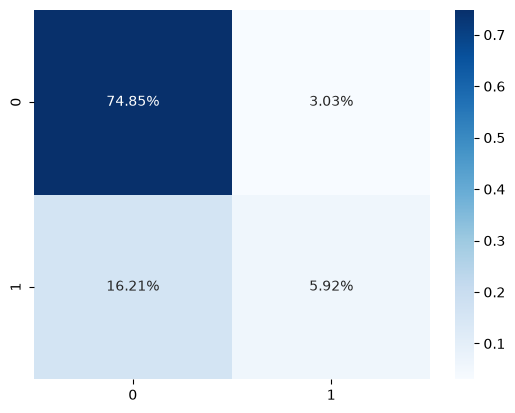

In [46]:
from sklearn.metrics import confusion_matrix
y_pred_svm = clf_svm.predict(x_test)
cf_matrix = confusion_matrix(y_test, y_pred_svm)
print(cf_matrix)
import seaborn as sns
sns.heatmap(cf_matrix/np.sum(cf_matrix), annot=True,
            fmt='.2%', cmap='Blues')
class_report = classification_report(y_test, y_pred_svm)
print("Classification Report SVM:")
print(class_report)

In [37]:
from sklearn.model_selection import GridSearchCV
param_grid = [
    {'C': [1, 10, 100, 1000], 'kernel': ['linear']},
    {'C': [1, 10, 100, 1000], 'gamma': [0.001, 0.0001], 'kernel': ['rbf']},
]
# Fast hyperparameter search
grid = GridSearchCV(
    svm.SVC(),
    param_grid=param_grid,
    cv=3,
    n_jobs=-1
)

grid.fit(x_train, y_train)

# Best parameters found
print(grid.best_params_)

# Refit final model with probabilities enabled
best_clf_SVM = svm.SVC(
    **grid.best_params_,
    probability=True
)

best_clf_SVM.fit(x_train, y_train)


{'C': 1, 'kernel': 'linear'}


c:\Users\Ronsa\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [47]:
print(f'Accuracy best svm - : {best_clf_SVM.score(x_test,y_test):.5f}')
print(f'Accuracy svm - : {clf_svm.score(x_test,y_test):.5f}')

Accuracy best svm - : 0.80712
Accuracy svm - : 0.80768


In [48]:
score_svm=best_clf_SVM.score(x_test,y_test)
print(f'R_squared of model is {score_svm}')
y_prob_svm = best_clf_SVM.predict(x_test).ravel()
y_pred_svm = (y_prob_svm > 0.5).astype(int)


print("ROC-AUC:", roc_auc_score(y_test, y_prob_svm))

R_squared of model is 0.807119021134594
ROC-AUC: 0.6126929076927816


[[6729  272]
 [1457  532]]
Classification Report SVM:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7001
           1       0.66      0.27      0.38      1989

    accuracy                           0.81      8990
   macro avg       0.74      0.61      0.63      8990
weighted avg       0.79      0.81      0.77      8990



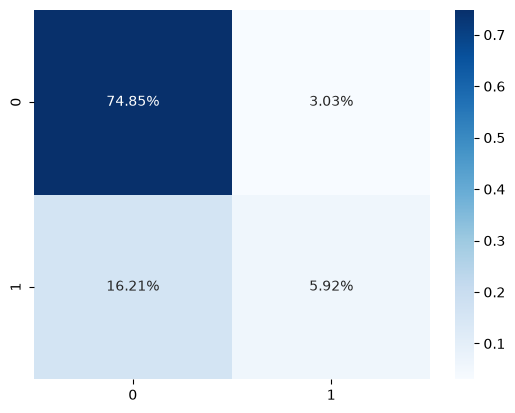

In [49]:
from sklearn.metrics import confusion_matrix
y_pred_svm = clf_svm.predict(x_test)
cf_matrix = confusion_matrix(y_test, y_pred_svm)
print(cf_matrix)
import seaborn as sns
sns.heatmap(cf_matrix/np.sum(cf_matrix), annot=True,
            fmt='.2%', cmap='Blues')
class_report = classification_report(y_test, y_pred_svm)
print("Classification Report SVM:")
print(class_report)

In [40]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Features selected from feature engineering
features = [
    'NumDelinq',
    'WorstPaymentStatus',
    'AvgUtil',
    'AGE',
    'EDUCATION'
]

target = 'default.payment.next.month'

# Scale features (important for DNNs)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

# Build DNN
model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),

    Dense(16, activation='relu'),
    Dropout(0.2),

    Dense(8, activation='relu'),

    Dense(1, activation='sigmoid')
])

# Compile
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Train
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

# Predictions
y_prob_dnn = model.predict(X_test_scaled).ravel()
y_pred_dnn = (y_prob_dnn > 0.5).astype(int)



Epoch 1/100


c:\Users\Ronsa\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7272 - loss: 0.5986 - val_accuracy: 0.7814 - val_loss: 0.5078
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7958 - loss: 0.4918 - val_accuracy: 0.8000 - val_loss: 0.4766
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7958 - loss: 0.4762 - val_accuracy: 0.8010 - val_loss: 0.4697
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7979 - loss: 0.4691 - val_accuracy: 0.8010 - val_loss: 0.4679
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7964 - loss: 0.4682 - val_accuracy: 0.7974 - val_loss: 0.4675
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7992 - loss: 0.4656 - val_accuracy: 0.7981 - val_loss: 0.4662
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7975 - loss: 0.4613 - val_accuracy: 0.7964 - val_loss: 0.4651
Epoch 8/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7978 - loss: 0.4626 - val_accuracy: 0.7976 - val_loss: 0.4

In [41]:
# Evaluation
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dnn))
print("Classification Report DNN:")
print(classification_report(y_test, y_pred_dnn))

ROC-AUC: 0.7426962060795883
Classification Report DNN:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7001
           1       0.65      0.28      0.39      1989

    accuracy                           0.81      8990
   macro avg       0.74      0.62      0.64      8990
weighted avg       0.79      0.81      0.78      8990



In [45]:

# Test tune 1
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

# Compile
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Train
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

# Predictions
y_prob_dnn2 = model.predict(X_test_scaled).ravel()
y_pred_dnn2 = (y_prob_dnn > 0.5).astype(int)

Epoch 1/100


c:\Users\Ronsa\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6431 - loss: 0.6482 - val_accuracy: 0.7666 - val_loss: 0.5315
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7946 - loss: 0.4859 - val_accuracy: 0.7983 - val_loss: 0.4753
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8023 - loss: 0.4648 - val_accuracy: 0.8012 - val_loss: 0.4678
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8010 - loss: 0.4620 - val_accuracy: 0.8038 - val_loss: 0.4646
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8010 - loss: 0.4581 - val_accuracy: 0.8038 - val_loss: 0.4630
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8008 - loss: 0.4569 - val_accuracy: 0.8031 - val_loss: 0.4634
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8016 - loss: 0.4578 - val_accuracy: 0.8031 - val_loss: 0.4619
Epoch 8/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8002 - loss: 0.4550 - val_accuracy: 0.8000 - val_loss: 0.4

In [46]:
# Evaluation
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dnn2))
print("Classification Report DNN:")
print(classification_report(y_test, y_pred_dnn2))

ROC-AUC: 0.7423643566253446
Classification Report DNN:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7001
           1       0.65      0.28      0.39      1989

    accuracy                           0.81      8990
   macro avg       0.74      0.62      0.64      8990
weighted avg       0.79      0.81      0.78      8990



In [57]:


# Test tune 1
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

# Compile
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Train
class_weight = {
    0: 1,
    1: 3
}

history = model.fit(
    X_train_scaled,
    y_train,
    class_weight=class_weight,
    validation_split=0.2,
    epochs=100,
    batch_size=256,
    callbacks=[early_stop]
)

# Predictions
y_prob_dnn2 = model.predict(X_test_scaled).ravel()
y_pred_dnn2 = (y_prob_dnn > 0.5).astype(int)


Epoch 1/100


c:\Users\Ronsa\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7412 - loss: 0.9024 - val_accuracy: 0.7385 - val_loss: 0.5760
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7497 - loss: 0.8635 - val_accuracy: 0.7607 - val_loss: 0.5358
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7533 - loss: 0.8604 - val_accuracy: 0.7368 - val_loss: 0.5661
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7456 - loss: 0.8513 - val_accuracy: 0.7387 - val_loss: 0.5424
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7424 - loss: 0.8526 - val_accuracy: 0.7375 - val_loss: 0.5489
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7445 - loss: 0.8467 - val_accuracy: 0.7392 - val_loss: 0.5361
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7404 - loss: 0.8528 - val_accuracy: 0.7371 - val_loss: 0.5473
Epoch 8/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7413 - loss: 0.8464 - val_accuracy: 0.7368 - val_loss: 0.5

In [59]:
# Evaluation
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dnn2))
print("Classification Report DNN:")
print(classification_report(y_test, y_pred_dnn2))

ROC-AUC: 0.7437010542701327
Classification Report DNN:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7001
           1       0.65      0.28      0.39      1989

    accuracy                           0.81      8990
   macro avg       0.74      0.62      0.64      8990
weighted avg       0.79      0.81      0.78      8990



281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 473us/step
[[6702  299]
 [1430  559]]
Classification Report DNN:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89      7001
           1       0.65      0.28      0.39      1989

    accuracy                           0.81      8990
   macro avg       0.74      0.62      0.64      8990
weighted avg       0.79      0.81      0.78      8990



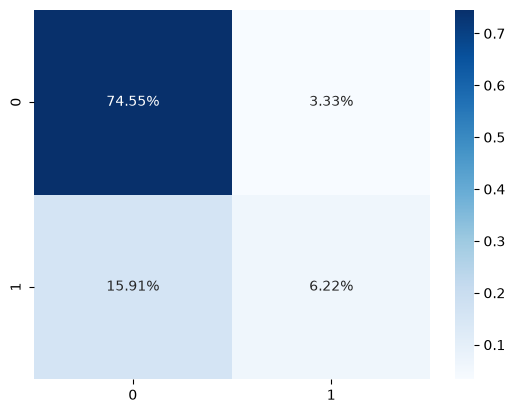

In [42]:
from sklearn.metrics import confusion_matrix

y_prob = model.predict(X_test_scaled).ravel()
y_pred = (y_prob > 0.5).astype(int)
cf_matrix = confusion_matrix(y_test, y_pred_dnn)
print(cf_matrix)
import seaborn as sns
sns.heatmap(cf_matrix/np.sum(cf_matrix), annot=True,
            fmt='.2%', cmap='Blues')
class_report = classification_report(y_test, y_pred_dnn)
print("Classification Report DNN:")
print(class_report)

In [43]:
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dnn))

ROC-AUC: 0.7426962060795883


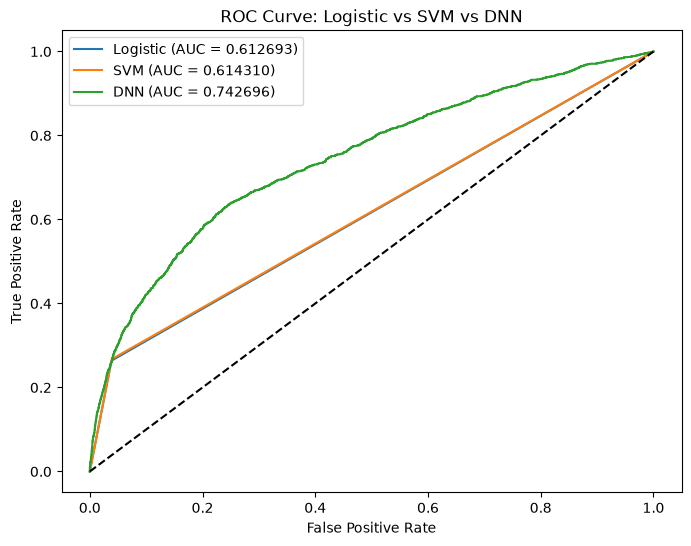

In [44]:


from sklearn.metrics import roc_curve, auc

y_pred_lr = clf_lr.predict(x_test)
y_prob_lr=clf_lr.predict(x_test).ravel()


# lr
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = auc(fpr_lr, tpr_lr)

# SVM
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
auc_svm = auc(fpr_svm, tpr_svm)

# dnn best
fpr_dnn, tpr_dnn, _ = roc_curve(y_test, y_prob_dnn)
auc_dnn = auc(fpr_dnn, tpr_dnn)



import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
# Logistic curve
plt.plot(fpr_lr, tpr_lr, label=f"Logistic (AUC = {auc_lr:.6f})")

# SVM curve
plt.plot(fpr_svm, tpr_svm, label=f"SVM (AUC = {auc_svm:.6f})")
# DNN
plt.plot(fpr_dnn, tpr_dnn, label=f"DNN (AUC = {auc_dnn:.6f})")

# random baseline
plt.plot([0,1], [0,1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Logistic vs SVM vs DNN")
plt.legend()
plt.show()